In [2]:
import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.model_selection import train_test_split
from tqdm.notebook import tqdm
from PIL import Image
import warnings

In [3]:
def load_model2():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    model = models.densenet121(weights='IMAGENET1K_V1')

    num_ftrs = model.classifier.in_features
    model.classifier = nn.Sequential(
        nn.Linear(num_ftrs, 1),
        nn.Sigmoid()
    )

    model.load_state_dict(torch.load('best_model.pth', map_location=device))
    model = model.to(device)
    model.eval()

    return model

In [4]:
def load_model():
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')  # ✅ add this
    model = models.densenet121(weights='IMAGENET1K_V1')
    num_ftrs = model.classifier.in_features
    model.classifier = nn.Linear(num_ftrs, 1)
    model.load_state_dict(torch.load('best_model.pth', map_location=device))
    return model.to(device).eval()

In [5]:
import cv2

class GradCAM:
    def __init__(self, model):
        self.model = model
        self.gradients = None
        self.activations = None

        # LAST CONV LAYER OF DENSENET
        target_layer = model.features.denseblock4

        target_layer.register_forward_hook(self.save_activation)
        target_layer.register_backward_hook(self.save_gradient)

    def save_activation(self, module, input, output):
        self.activations = output

    def save_gradient(self, module, grad_in, grad_out):
        self.gradients = grad_out[0]

    def generate(self, input_tensor):
        output = self.model(input_tensor)

        self.model.zero_grad()
        output.backward()

        grads = self.gradients
        acts = self.activations

        weights = grads.mean(dim=(2,3), keepdim=True)
        cam = (weights * acts).sum(dim=1)

        cam = torch.relu(cam)
        cam = cam.squeeze().cpu().detach().numpy()

        cam = cv2.resize(cam, (224,224))
        cam = (cam - cam.min()) / (cam.max() + 1e-8)

        return cam

In [6]:
import matplotlib.pyplot as plt
from torch import device

def visualize_prediction(volume_id, slice_index=50):

    model = load_model()
    gradcam = GradCAM(model)
    

    vol_df = df[df['volume'] == volume_id].reset_index(drop=True)

    if len(vol_df) == 0:
        print("❌ Volume not found")
        return

    if slice_index >= len(vol_df):
        print("❌ Slice index out of range")
        return

    row = vol_df.iloc[slice_index]

    # LOAD IMAGE
    with h5py.File(row['slice_path'], 'r') as f:
        key = 'image' if 'image' in f.keys() else list(f.keys())[0]
        img = np.array(f[key])

    # FIX SHAPE
    if img.shape[-1] <= 4:
        img = np.transpose(img, (2,0,1))

    img = img[:3]

    # NORMALIZE
    img = img.astype(np.float32)
    if img.max() > 1:
        img /= 255.0

    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    img_tensor = torch.tensor(img, dtype=torch.float32).unsqueeze(0).to(device)

    # RESIZE
    img_tensor = torch.nn.functional.interpolate(img_tensor, size=(224,224))

    # --------------------
    # PREDICTION
    # --------------------
    output = torch.sigmoid(model(img_tensor)).item()
    pred = "TUMOR" if output > 0.5 else "NO TUMOR"

    # --------------------
    # GRAD-CAM
    # --------------------
    cam = gradcam.generate(img_tensor)

    img_np = img_tensor.squeeze().permute(1,2,0).cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() + 1e-8)

    heatmap = cv2.applyColorMap(np.uint8(255 * cam), cv2.COLORMAP_JET)
    heatmap = heatmap / 255.0

    overlay = heatmap * 0.4 + img_np
    overlay = np.clip(overlay, 0, 1)   # ✅ FIX 

    # --------------------
    # DISPLAY
    # --------------------
    plt.figure(figsize=(10,4))

    plt.subplot(1,2,1)
    plt.title("Original")
    plt.imshow(img_np)
    plt.axis('off')

    plt.subplot(1,2,2)
    plt.title(f"{pred} (Grad-CAM)")
    plt.imshow(overlay)
    plt.axis('off')

    plt.show()

    print(f"Prediction Score: {output:.4f}")
    print(f"Final Prediction: {pred}")

In [7]:
from torchvision import transforms

transform_val = transforms.Compose([
    transforms.Resize((224, 224))
])

In [8]:
from torch.utils.data import Dataset

class BraTSDataset(Dataset):
    def __init__(self, dataframe, transform=None):
        self.df = dataframe
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        with h5py.File(row['slice_path'], 'r') as f:
            key = 'image' if 'image' in f.keys() else list(f.keys())[0]
            img = np.array(f[key])

        if img.shape[-1] <= 4:
            img = np.transpose(img, (2,0,1))
        img = img[:3].astype(np.float32)
        if img.max() > 1: img /= 255.0

        img = torch.tensor(img)
        if self.transform: img = self.transform(img)

        label = torch.tensor(row['target'], dtype=torch.float32)
        return img, label

In [9]:
def predict_patient_volume(volume_id):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    print(f'Using device: {device}')

    model = load_model()

    vol_df = df[df['volume'] == volume_id]

    if len(vol_df) == 0:
        print("❌ Volume not found")
        return

    dataset = BraTSDataset(vol_df, transform=transform_val)
    loader = DataLoader(dataset, batch_size=8)

    preds = []

    with torch.no_grad():
        for images, _ in loader:
            images = images.to(device)
            outputs = torch.sigmoid(model(images)).squeeze()
            preds.extend((outputs > 0.5).cpu().numpy())
            
    tumor_percent = np.mean(preds) * 100

    print(f"Volume: {volume_id}")
    print(f"Tumor Slice %: {tumor_percent:.2f}%")

    if tumor_percent > 5:
        print(">>> TUMOR DETECTED")
    else:
        print(">>> NO TUMOR")

In [10]:
import pandas as pd
import os
metadata_path = 'BraTS20 Training Metadata.csv'
data_dir = 'BraTS2020_training_data/content/data'
df = pd.read_csv(metadata_path)
df['slice_path'] = df['slice_path'].apply(lambda x: os.path.join(data_dir, os.path.basename(x)))

print(df['volume'].unique()[:10])  # now works

[ 41 185 135 306  40 140 359 310 249  95]


In [11]:
print(df['volume'].unique())

[ 41 185 135 306  40 140 359 310 249  95 235 286  28 159 275 251 265 190
   9 325 155  64 291 319 264 358 122  50 278 214  82 193 169  88 352 323
 299  92   2 163 341 124  56 314 315   7 100 107 259  26  33 168 326 238
 295  23  29  37 246 228 297   1 156 129 236 307 173  27 274 149 172 254
  25  83  15  93  63 354 322 229 151 105  17 188 148 234 113 125 115  70
  32 348 342 240 260 206  55 131 130  96  39 154 121 177 139 106 153 288
 143 227 186 294 343 237 119 120  20 304 300 179 182 202  11  81 134  42
 152 331 141 313 329 293 276 195 281 167  13 262  51 302 273 285  91 339
  30 111 337 318 197 175 165  52 361 316  99  35 180 123 174 145  45  46
 346 209 114 349 219  78 324 267  43  77 116 340 261 118  18  86 204 187
 287 208  14 311  54  87 132  34 305 296  36 242 309 217 336  24 362  48
  19  73 328 103  69   8 226   5 256  61  89 158 298 223 161 280 117  31
 176  66  85 345 184 146 344  22 112  94 142 222 338 207 279 232 272 127
 327  80  58  21 353 284 189  44 164 360 282 351 35

In [15]:
def visualize_unet(volume_id, slice_index=50):

    vol_df = df[df['volume'] == volume_id].reset_index(drop=True)

    if len(vol_df) == 0:
        print("❌ Volume not found")
        return

    if slice_index >= len(vol_df):
        print("❌ Slice index out of range")
        return

    row = vol_df.iloc[slice_index]

    # LOAD FROM H5
    with h5py.File(row['slice_path'], 'r') as f:
        img = np.array(f['image'])
        mask = np.array(f['mask'])

    # -------- IMAGE FIX --------
    img = np.transpose(img, (2,0,1))[:3]
    img = img.astype(np.float32)
    for c in range(img.shape[0]):
        mask_c = img[c] > 0
        if mask_c.any():
            mean = img[c][mask_c].mean()
            std = img[c][mask_c].std()
            if std > 0:
                img[c][mask_c] = (img[c][mask_c] - mean) / std

    # -------- MASK FIX --------
    if len(mask.shape) == 3:
        mask = np.max(mask, axis=2)

    mask = (mask > 0).astype(np.float32)

    # -------- RESIZE (same as training) --------
    img_tensor = torch.tensor(img).unsqueeze(0)
    mask_tensor = torch.tensor(mask).unsqueeze(0).unsqueeze(0)

    img_tensor = torch.nn.functional.interpolate(img_tensor, size=(128,128))
    mask_tensor = torch.nn.functional.interpolate(mask_tensor, size=(128,128), mode='nearest')

    img_tensor = img_tensor.to(device)

    # -------- PREDICTION --------
    with torch.no_grad():
        pred = unet(img_tensor)
        pred = torch.sigmoid(pred)   # 🔥 IMPORTANT (since logits)

    pred = pred.squeeze().cpu().numpy()
    mask = mask_tensor.squeeze().cpu().numpy()

    # -------- VISUALIZATION --------
    img_np = img_tensor.squeeze().permute(1,2,0).cpu().numpy()
    img_np = (img_np - img_np.min()) / (img_np.max() + 1e-8)

    plt.figure(figsize=(12,4))

    plt.subplot(1,3,1)
    plt.title("Image")
    plt.imshow(img_np)
    plt.axis('off')

    plt.subplot(1,3,2)
    plt.title("True Mask")
    plt.imshow(mask, cmap='gray')
    plt.axis('off')

    plt.subplot(1,3,3)
    plt.title("Predicted Mask")
    plt.imshow(pred > 0.5, cmap='gray')
    plt.axis('off')

    plt.show()

    # -------- TUMOR AREA --------
    tumor_pixels = np.sum(pred > 0.5)
    print(f"Tumor Pixel Count: {tumor_pixels}")
    print("Pred min:", pred.min(), "max:", pred.max())

Using device: cuda
Volume: 93
Tumor Slice %: 40.65%
>>> TUMOR DETECTED


Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [0.0..1.0647192].


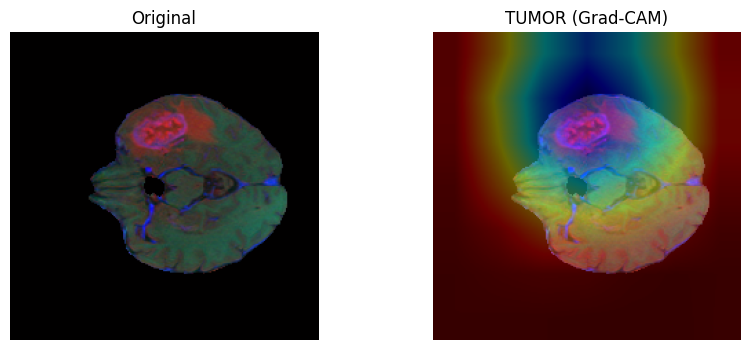

Prediction Score: 1.0000
Final Prediction: TUMOR


In [19]:
test_volume =93  # 👈 any ID you want from list
slice_indexselected = 56  # 👈 any slice index you want (0 to ~155)
predict_patient_volume(test_volume)
visualize_prediction(test_volume, slice_index=slice_indexselected)
